# Step 17: reading "I" and "we" in context (BERT)

Exploratory, added after the main analysis was frozen. The we-share counts words, not meaning: in Kobe Bryant's "It is not me at the forefront", *me* counts as self-focus although he is giving the credit away. Here every counted "I" and "we" gets a contextual embedding from `bert-base-uncased`, and a classifier sorts each one into **self**, **team** or **neither** (conversation). The tier comparison is then rerun on a context-corrected we-share.

**All labels in this step come from AI models** (a blind labelling agent, checked by a second blind agent and by Claude); there is no human check. Method, rules and prediction were written in the Doc tab *Step 17* before any tier result.

Pipeline: `scripts/bert_pronouns.py` (embed, sweep, sheets, search, wecheck, labelsheet, train, model). This notebook only reads its saved outputs.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
DATA = Path('..') / 'data'
pd.set_option('display.width', 140)

## 1. The embeddings

219,191 vectors (111,278 "I", 107,913 "we"): one per word the we-share counts, the mean of BERT's last four layers over the word's pieces, with the whole answer as context. The counts were checked to equal `i_count` and `we_count`.

In [2]:
idx = pd.read_csv(DATA / 'bert_pronoun_index.csv')
idx.groupby(['family', 'word']).size().rename('uses').to_frame().T

family      i                                                      we                                                     
word        i  i'd  i'll   i'm  i've     me mine     my myself    our ours ourselves     us     we we'd we'll  we're we've
uses    72310  270  1232  9836  4026  11023   95  10654   1832  12630   83      1367  12980  60867  140  2399  10019  7428

## 2. Clustering first (descriptive)

k-means on the vectors (word-form means removed, PCA 50). Stability across 5 seeds (adjusted Rand index) and silhouette by K:

In [3]:
pd.read_csv(DATA / 'bert_sweep.csv')

,family,k,n,ari,silhouette,smallest_pct,largest_pct
0,i,4,111278,0.557,0.076,22.4,31.6
1,i,6,111278,0.775,0.076,10.6,21.5
2,i,8,111278,0.769,0.078,6.2,18.6
3,i,10,111278,0.679,0.079,3.1,17.5
4,i,12,111278,0.833,0.078,3.1,11.3
5,we,4,107913,0.650,0.055,20.3,31.8
6,we,6,107913,0.699,0.058,12.9,21.8
7,we,8,107913,0.982,0.055,9.9,13.9
8,we,10,107913,0.644,0.053,7.7,12.3
9,we,12,107913,0.709,0.051,6.3,10.7


Silhouette stays at 0.05 to 0.08 for every K: the uses do not form separate groups. Reading the clusters (sheets in `data/bert_sheets/`) showed that they split by grammar and position ("I think" + a statement, "I mean", "like I said", "my / myself"), not by self against team, and the 10 non-team "we" from the Step 12 check spread over four "we" clusters:

In [4]:
print((DATA / 'bert_wecheck.txt').read_text(encoding='utf-8'))

The 90 hand-coded "we" uses (Step 12) by BERT "we" cluster; matched 90 of 90

referent  generic  other_group  team  All
cluster                                  
1               0            0     8    8
2               0            2    10   12
3               0            0    10   10
4               0            0     8    8
5               0            0     6    6
6               2            3    17   22
7               0            2    14   16
8               1            0     7    8
All             3            7    80   90



So the main measure became **supervised**: label examples, train a classifier, label every use.

## 3. Labels and agreement

720 uses (300 random + 60 targeted for each word type), labelled blind by an AI agent. A second blind agent labelled 220 of them (the 100 random ones Claude also labelled, and the 120 targeted ones). Agreement:

In [5]:
log = (DATA / 'bert_train.log').read_text(encoding='utf-8')
print('\n'.join(l for l in log.splitlines() if l.startswith('Agreement')))

Agreement, AI agent vs Claude, "I", random (47 uses): 98%, Cohen's kappa 0.96
Agreement, AI agent vs Claude, "we", random (53 uses): 98%, Cohen's kappa 0.85
Agreement, AI agent vs AI agent 2, "I", random (47 uses): 100%, Cohen's kappa 1.00
Agreement, AI agent vs AI agent 2, "I", targeted (60 uses): 82%, Cohen's kappa 0.65
Agreement, AI agent vs AI agent 2, "we", random (53 uses): 100%, Cohen's kappa 1.00
Agreement, AI agent vs AI agent 2, "we", targeted (60 uses): 93%, Cohen's kappa 0.81
Agreement, Claude vs AI agent 2, "I", random (47 uses): 98%, Cohen's kappa 0.96
Agreement, Claude vs AI agent 2, "we", random (53 uses): 98%, Cohen's kappa 0.85


Near-perfect on ordinary uses; lower on the targeted rare kinds of "I" (kappa 0.65), mostly a player naming himself in a list with teammates (self or team?). Team-type "I" is about 3% of all "I", so this boundary moves the measure little.

## 4. The classifier

Logistic regression on the 768 BERT numbers, 5-fold cross-validation split by player (always tested on players it never saw). The bar, written in advance: macro-F1 at least 0.60 and accuracy above always guessing the most common label.

In [6]:
print('\n'.join(l for l in log.splitlines() if l.startswith(('chosen', 'all "', 'label shares'))))

chosen C = 1.0; held-out players: macro-F1 0.776 (all labelled), random part: accuracy 0.897 vs majority class 0.600, macro-F1 0.738  ->  PASSES the bar (macro-F1 >= 0.60 and above majority)
label shares in the random sample (training labels): self 60%, neither 35%, team 5%
all "I" uses labelled by the model: self 59.0%, neither 37.8%, team 3.2%
chosen C = 0.1; held-out players: macro-F1 0.714 (all labelled), random part: accuracy 0.940 vs majority class 0.950, macro-F1 0.684  ->  FAILS the bar (macro-F1 >= 0.60 and above majority)
label shares in the random sample (training labels): team 95%, not_team 5%
all "we" uses labelled by the model: team 95.4%, not_team 4.6%


"I" passes. "We" fails (0.94 against 0.95 for calling every "we" team), so it is not used and every "we" counts as team, as in the original measure.

**Context-corrected we-share** = (team "I" + all "we") / (self "I" + team "I" + all "we"): conversational "I" is left out and credit-giving "I" moves to the team side.

## 5. How "I" is used, by tier

In [7]:
mix = pd.read_csv(DATA / 'bert_i_mix.csv', index_col=0)
mix.index = mix.index.str.replace('i:', '')
mix.round(1)  # % of each tier's "I" words, pooled

,role,starter,superstar
label,,,
neither,38.1,40.7,35.9
self,59.0,56.1,60.7
team,2.9,3.2,3.4


About 38% of "I" words are conversation in every tier. Counting them as self-focus added noise, not a difference between tiers.

## 6. The tier comparison

In [8]:
e = pd.read_csv(DATA / 'bert_effects.csv')
s = e[e.tier == 'superstar'][['analysis', 'spec', 'diff', 'diff_lo', 'diff_hi', 'p', 'n_units', 'n_players']].copy()
for c in ['diff', 'diff_lo', 'diff_hi']:
    s[c] = (100 * s[c]).round(1)
s.rename(columns={'diff': 'superstar - role (points)', 'diff_lo': 'lo', 'diff_hi': 'hi'})

,analysis,spec,superstar - role (points),lo,hi,p,n_units,n_players
2,A corrected we-share,1 Tier only,-1.1,-6.5,4.3,0.688443,4415,377
5,A corrected we-share,2 + game and round,-1.1,-5.9,3.7,0.660528,4415,377
8,A corrected we-share,3 + question 'you' rate,-0.4,-4.7,4.0,0.872918,4415,377
11,A corrected we-share,4 + question topics,-0.5,-4.5,3.6,0.818095,4415,377
14,"A original we-share, same units",4 + question topics,-0.4,-3.9,3.0,0.816984,4415,377
17,"B corrected we-share, same player (FE)",4 + question topics,0.9,-4.4,6.2,0.745981,4398,361


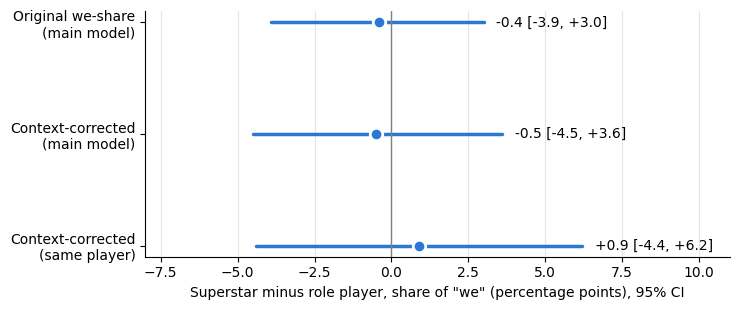

In [9]:
rows = [('Original we-share\n(main model)', 'A original we-share, same units'),
        ('Context-corrected\n(main model)', 'A corrected we-share'),
        ('Context-corrected\n(same player)', 'B corrected we-share, same player (FE)')]
full = s[s.spec == '4 + question topics'].set_index('analysis')
fig, ax = plt.subplots(figsize=(7.5, 3.2))
for k, (label, key) in enumerate(rows):
    r = full.loc[key]
    ax.plot([r.diff_lo, r.diff_hi], [k, k], color='#2a78d6', lw=2.5, solid_capstyle='round')
    ax.plot(r['diff'], k, 'o', color='#2a78d6', ms=9, mec='white', mew=2)
    ax.text(r.diff_hi + 0.4, k, f"{r['diff']:+.1f} [{r.diff_lo:+.1f}, {r.diff_hi:+.1f}]", va='center', fontsize=10)
ax.axvline(0, color='0.5', lw=1)
ax.set_yticks(range(len(rows)), [r[0] for r in rows])
ax.invert_yaxis()
ax.set_xlim(-8, 11)
ax.set_xlabel('Superstar minus role player, share of "we" (percentage points), 95% CI')
for sp in ['top', 'right']:
    ax.spines[sp].set_visible(False)
ax.grid(axis='x', color='0.9')
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(Path('..') / 'figures' / 'bert_superstar_vs_role.png', dpi=200)
plt.show()

## Reading

The null holds when "I" and "we" are read in context: superstar minus role is about zero on the original we-share (-0.4 points) and on the context-corrected one (-0.5 points, 95% CI -4.5 to +3.6; same player +0.9). The prediction (superstars higher) is not supported. Limits: exploratory and added after the freeze; every label comes from AI models with no human check; the classifier finds only about half of the rare credit-giving "I"; the "we" classifier was not used.

## 7. Step 18: the BERT measure becomes the main measure

On 18 Nov the context-corrected measure ("team-focused share") was made the main measure of the talk, after both main results were known; they agree. The situation effects and the 14 Step 9 robustness checks were rerun on it with `scripts/bert_main.py`, which reuses the existing model code with the counts swapped (self "I" for "I", team side for "we") and first checks that it reproduces the Step 17 result exactly.

In [10]:
txt = (DATA / 'bert_main_results.txt').read_text(encoding='utf-8')
print(txt.split('Robustness')[0])

Step 18: main measure = share of team-focused pronouns (BERT sides), (team "I" + all "we") / (self "I" + team "I" + all "we"); conversational "I" left out.
Units with any self- or team-side pronoun: 4,415 of 4,425; players 377

Check: model A on the swapped units reproduces Step 17 exactly: superstar minus role -0.48 pp [-4.53, +3.58]
Adjusted share by tier (all controls): role 0.650 [0.628, 0.671], starter 0.656 [0.637, 0.674], superstar 0.645 [0.609, 0.681]

Unit share: mean 0.671, SD 0.247 (24.7 points) over 4,415 units
Pooled game-day share: after losses 0.731, after wins 0.603
Raw unit means by tier: role 0.661, starter 0.683, superstar 0.666

Situation effects (average marginal effects, percentage points of the share, 95% CI):
   Superstar vs role player                 -0.5 [-4.5, +3.6]  (n 4415)
   Won vs lost (game days)                  -9.1 [-11.8, -6.3]  (n 2081)
   +10 points scored (game days)            -2.5 [-3.9, -1.0]  (n 2081)
   +10 'you' per 1,000 question words   

In [11]:
rb = pd.read_csv(DATA / 'bert_robustness.csv')[['group', 'check', 'diff', 'diff_lo', 'diff_hi', 'p', 'n_units', 'n_players']]
for c in ['diff', 'diff_lo', 'diff_hi']:
    rb[c] = (100 * rb[c]).round(1)
rb.round({'p': 3})  # superstar minus role, points of team-focused share

,group,check,diff,diff_lo,diff_hi,p,n_units,n_players
0,Main,"Main result (model A, all controls)",-0.5,-4.5,3.6,0.818,4415,377
1,Measure,Counting words instead (the plain we-share),-0.4,-3.9,3.0,0.817,4415,377
2,Status definition,Superstar = All-NBA that season,-1.3,-6.1,3.4,0.580,4415,377
3,Status definition,"All-NBA, same player (fixed effects)",-0.6,-6.8,5.5,0.841,4398,361
4,Status definition,Two groups: superstar vs everyone else,-0.9,-4.6,2.8,0.640,4415,377
5,Status definition,Role players who were never All-Stars,-0.1,-4.3,4.2,0.976,4143,360
6,Which press conferences,Game days only,6.2,1.5,10.9,0.009,2081,279
7,Which press conferences,Non-game days only,-4.7,-9.4,0.1,0.052,2333,320
8,Which press conferences,"Game days, same player (fixed effects)",4.2,-6.5,14.9,0.432,2064,264
9,Which press conferences,"Non-game days, same player (fixed effects)",-0.5,-6.0,5.0,0.852,2321,308


Same conclusion on the main measure: 13 of 14 checks include zero; the exception is again game days only (+6.2 points), where role players speak after their own big games (+5.3 points above their own average).